# A1 — Vision Transformers: ViT do zero, ViT pré-treinado e CNN

**Disciplina:** Visão Computacional com CNNs e Transformers

**Requisitos de execução**
- **GPU:** Colab T4 (Runtime > Change runtime type > T4 GPU). Em CPU o treino é inviável.
- **Memória:** ~6 GB de RAM, ~8 GB de VRAM (pico medido de 7,2 GB no fine-tuning do ViT-B/16) e ~1 GB de disco.
- **Tempo estimado:** ~20 minutos de execução completa em T4 (medido: 18,6 min, incluindo download, 3 treinamentos e análises de atenção). O tempo real é impresso na última seção.
- **Pré-requisito:** secret `KAGGLE_API_TOKEN` no Colab (ou o `.zip` do dataset na pasta do projeto no Google Drive).
- **Domínio:** Varejo. **Dataset:** [Fashion Product Images (Small)](https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small) — fotos de produtos de moda e-commerce, com o tipo de artigo (`articleType`) como rótulo.

**Uso de IA:** O assistente Claude (Anthropic) foi utilizado como apoio na estruturação do código e na revisão dos textos deste notebook.

## Objetivo e roteiro

Implementar um Vision Transformer (ViT) do zero em PyTorch, treiná-lo em um problema de classificação de produtos de varejo e compará-lo com (i) um ViT pré-treinado (`google/vit-base-patch16-224-in21k`) ajustado por fine-tuning e (ii) uma CNN pré-treinada (ResNet-18).

1. Ambiente e dataset
2. Pré-processamento e divisão dos dados
3. Componentes do ViT implementados do zero e testes unitários
4. Funções de treino e avaliação
5. Experimento 1: ViT do zero
6. Experimento 2: ViT-B/16 pré-treinado (fine-tuning)
7. Experimento 3: ResNet-18 pré-treinada
8. Comparação dos resultados e análise de erros
9. Visualização da atenção
10. Pré-treino em texto (BERT) vs. imagem (ViT), DeiT e Swin
11. Tempo total, referências e declaração de uso de IA

## 1. Ambiente e dataset

In [ ]:
import os
import sys
import glob
import math
import time
import random
import zipfile
import subprocess
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

NOTEBOOK_START = time.time()

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("Aviso: rodando em CPU. Selecione GPU (T4) em Runtime > Change runtime type.")

print(f"PyTorch: {torch.__version__} | Torchvision: {torchvision.__version__}")
print(f"Pandas: {pd.__version__} | NumPy: {np.__version__} | Scikit-learn: {sklearn.__version__}")

Device: cuda
GPU: Tesla T4
PyTorch: 2.11.0+cu130 | Torchvision: 0.26.0+cu130
Pandas: 2.2.3 | NumPy: 2.1.3 | Scikit-learn: 1.6.1


In [ ]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers"], check=True)
import transformers
from transformers import ViTForImageClassification, AutoImageProcessor

print(f"Transformers: {transformers.__version__}")

Transformers: 5.18.0


### Download do dataset

O dataset é baixado pela API do Kaggle. Adicione nos *Secrets* do Colab (ícone de chave na barra lateral) um segredo chamado `KAGGLE_API_TOKEN` com o token da sua conta Kaggle e ative *Notebook access*.

Alternativa sem token: baixe o `.zip` em https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small e coloque-o na pasta `PROJECT_DIR` do Google Drive; a célula o extrai automaticamente.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/1_vision_transformers"
os.makedirs(PROJECT_DIR, exist_ok=True)

DATA_DIR = "/content/a1_data"

try:
    from google.colab import userdata

    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "kaggle"], check=True)
    subprocess.run(
        ["kaggle", "datasets", "download", "-d", "paramaggarwal/fashion-product-images-small", "-p", DATA_DIR, "--unzip"],
        check=True,
    )
except Exception:
    zip_files = glob.glob(f"{PROJECT_DIR}/*.zip")
    assert zip_files, "Configure o secret KAGGLE_API_TOKEN ou coloque o .zip do dataset em PROJECT_DIR."
    with zipfile.ZipFile(zip_files[0]) as z:
        z.extractall(DATA_DIR)

print("Dataset pronto em:", DATA_DIR)

Mounted at /content/drive
Dataset pronto em: /content/a1_data


In [ ]:
styles_candidates = glob.glob(f"{DATA_DIR}/**/styles.csv", recursive=True)
assert styles_candidates, "styles.csv não encontrado."
STYLES_PATH = styles_candidates[0]
IMAGES_DIR = os.path.join(os.path.dirname(STYLES_PATH), "images")
assert os.path.isdir(IMAGES_DIR), "Pasta images não encontrada ao lado de styles.csv."

styles = pd.read_csv(STYLES_PATH, on_bad_lines="skip")
styles["path"] = styles["id"].astype(str).map(lambda i: os.path.join(IMAGES_DIR, f"{i}.jpg"))
styles = styles[styles["path"].map(os.path.exists)].dropna(subset=["articleType"]).reset_index(drop=True)

print(f"Registros com imagem disponível: {len(styles)}")
print(f"Tipos de artigo distintos: {styles['articleType'].nunique()}")
styles[["id", "gender", "masterCategory", "subCategory", "articleType", "baseColour"]].head()

Registros com imagem disponível: 44419
Tipos de artigo distintos: 142


,id,gender,masterCategory,subCategory,articleType,baseColour
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue
1,39386,Men,Apparel,Bottomwear,Jeans,Blue
2,59263,Women,Accessories,Watches,Watches,Silver
3,21379,Men,Apparel,Bottomwear,Track Pants,Black
4,53759,Men,Apparel,Topwear,Tshirts,Grey


### Seleção das classes

O catálogo é bastante desbalanceado. Para obter um problema de classificação com dificuldade realista e treino rápido no Colab, são usadas as **20 classes de `articleType` mais frequentes**, com no máximo **1.000 imagens por classe** (amostragem aleatória com semente fixa). As imagens originais têm ~60×80 px e são preenchidas com branco até ficarem quadradas e redimensionadas para **80×80**, tamanho divisível pelo patch de 8×8 usado no ViT do zero (grade de 10×10 patches).

In [ ]:
NUM_CLASSES = 20
MAX_PER_CLASS = 1000
IMAGE_SIZE = 80

top_types = styles["articleType"].value_counts().head(NUM_CLASSES).index.tolist()
subset = styles[styles["articleType"].isin(top_types)]
subset = (
    subset.sample(frac=1.0, random_state=SEED)
    .groupby("articleType")
    .head(MAX_PER_CLASS)
    .reset_index(drop=True)
)

CLASS_NAMES = sorted(top_types)
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
subset["label"] = subset["articleType"].map(class_to_idx)

print(f"Imagens no subconjunto: {len(subset)}")
counts_full = styles[styles["articleType"].isin(CLASS_NAMES)]["articleType"].value_counts().reindex(CLASS_NAMES)
counts_used = subset["articleType"].value_counts().reindex(CLASS_NAMES)
pd.DataFrame({"disponíveis": counts_full, "usadas": counts_used})

Imagens no subconjunto: 17677


,disponíveis,usadas
articleType,,
Backpacks,724,724
Belts,813,813
Briefs,849,849
Casual Shoes,2845,1000
Flip Flops,914,914
Formal Shoes,637,637
Handbags,1759,1000
Heels,1323,1000
Jeans,608,608


In [ ]:
def load_square(path, size=IMAGE_SIZE):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    side = max(w, h)
    canvas = Image.new("RGB", (side, side), (255, 255, 255))
    canvas.paste(img, ((side - w) // 2, (side - h) // 2))
    return np.asarray(canvas.resize((size, size), Image.BILINEAR), dtype=np.uint8)


t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as pool:
    images = list(pool.map(load_square, subset["path"].tolist()))

X_all = np.stack(images)
y_all = subset["label"].to_numpy()
print(f"X: {X_all.shape} {X_all.dtype} | y: {y_all.shape} | carregamento: {time.time() - t0:.0f}s")

X: (17677, 80, 80, 3) uint8 | y: (17677,) | carregamento: 13s


### Análise exploratória

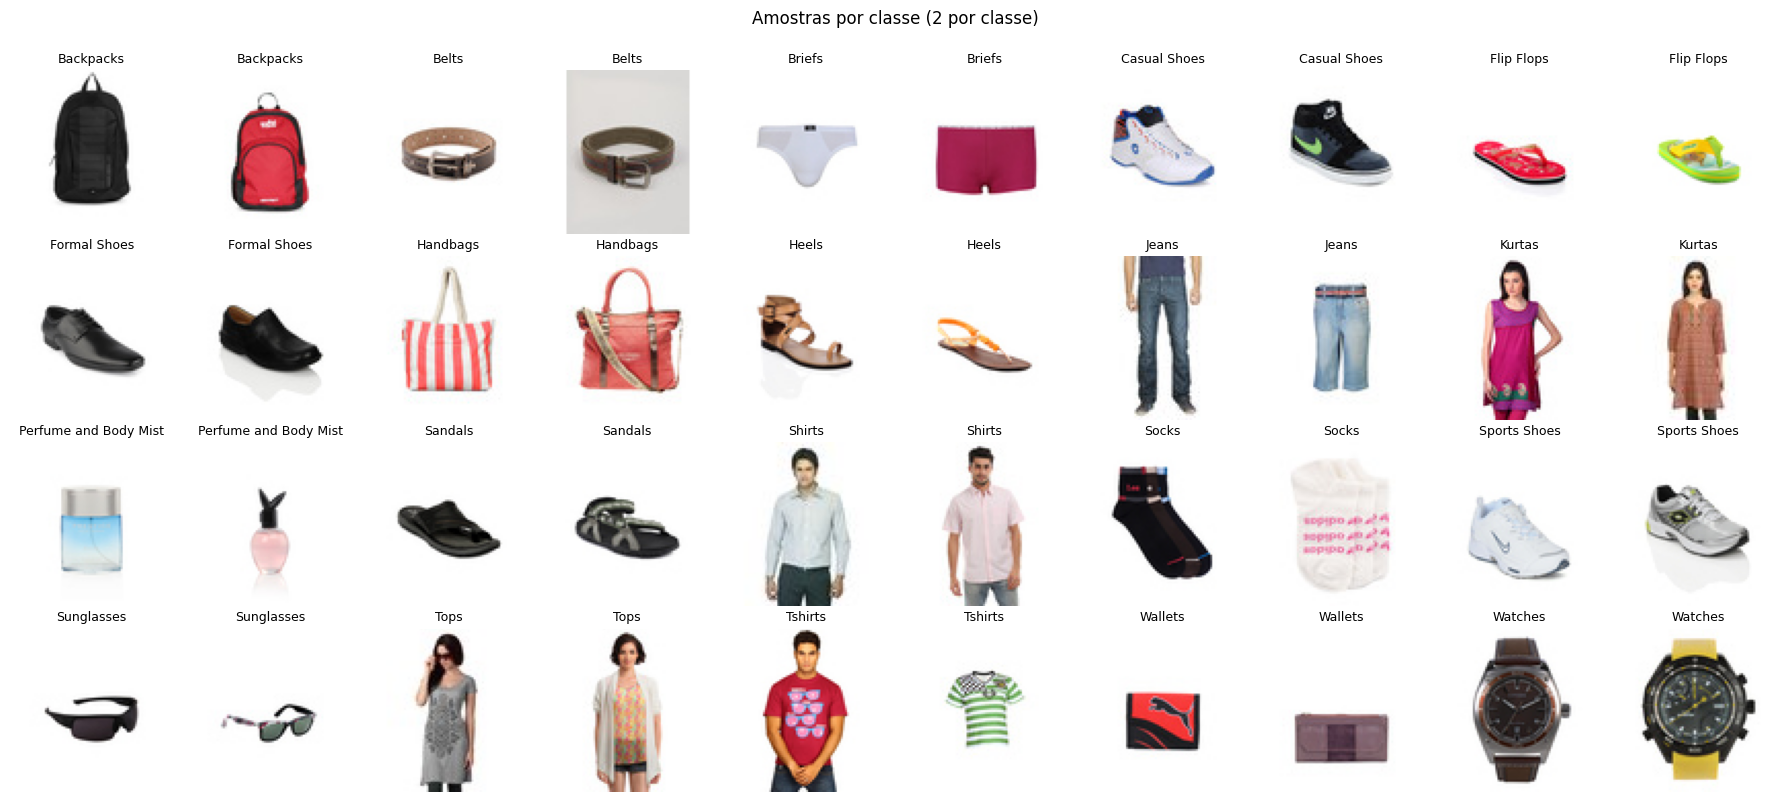

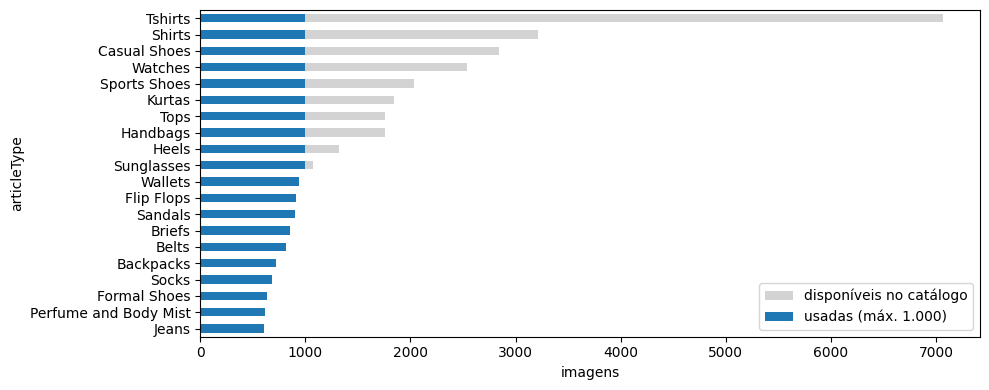

In [ ]:
fig, axes = plt.subplots(4, 10, figsize=(18, 8))
rng = np.random.RandomState(SEED)
for ax, c in zip(axes.flat, [c for c in range(NUM_CLASSES) for _ in range(2)]):
    idx = rng.choice(np.where(y_all == c)[0])
    ax.imshow(X_all[idx])
    ax.set_title(CLASS_NAMES[c], fontsize=9)
    ax.axis("off")
plt.suptitle("Amostras por classe (2 por classe)", y=1.0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
counts_full.sort_values().plot.barh(ax=ax, color="lightgray", label="disponíveis no catálogo")
counts_used.reindex(counts_full.sort_values().index).plot.barh(ax=ax, color="tab:blue", label="usadas (máx. 1.000)")
ax.set_xlabel("imagens")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Divisão dos dados e pré-processamento

A divisão é **estratificada** em 70% treino, 15% validação e 15% teste. A validação escolhe o melhor checkpoint de cada modelo; o teste é usado uma única vez, ao final, para a comparação. O conjunto inteiro (uint8) é mantido na GPU e as transformações são feitas em lote, o que elimina o gargalo de leitura de disco.

**Augmentation** (somente no treino): zoom aleatório entre 70% e 100% da imagem, deslocamento de até 10% e espelhamento horizontal. A normalização usa média e desvio calculados no treino para o ViT do zero e as estatísticas apropriadas de cada modelo pré-treinado.

In [ ]:
idx_all = np.arange(len(y_all))
idx_train, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=y_all, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=y_all[idx_tmp], random_state=SEED)

X_gpu = torch.from_numpy(X_all).permute(0, 3, 1, 2).contiguous().to(device)
y_gpu = torch.from_numpy(y_all).long().to(device)

X_train, y_train = X_gpu[idx_train], y_gpu[idx_train]
X_val, y_val = X_gpu[idx_val], y_gpu[idx_val]
X_test, y_test = X_gpu[idx_test], y_gpu[idx_test]

train_float = X_train.float() / 255
MEAN_LOCAL = train_float.mean(dim=(0, 2, 3)).tolist()
STD_LOCAL = train_float.std(dim=(0, 2, 3)).tolist()
del train_float

print(f"Treino: {len(idx_train)} | Validação: {len(idx_val)} | Teste: {len(idx_test)}")
print(f"Média (treino): {np.round(MEAN_LOCAL, 3)} | Desvio (treino): {np.round(STD_LOCAL, 3)}")

Treino: 12373 | Validação: 2652 | Teste: 2652
Média (treino): [0.895 0.883 0.879] | Desvio (treino): [0.238 0.251 0.255]


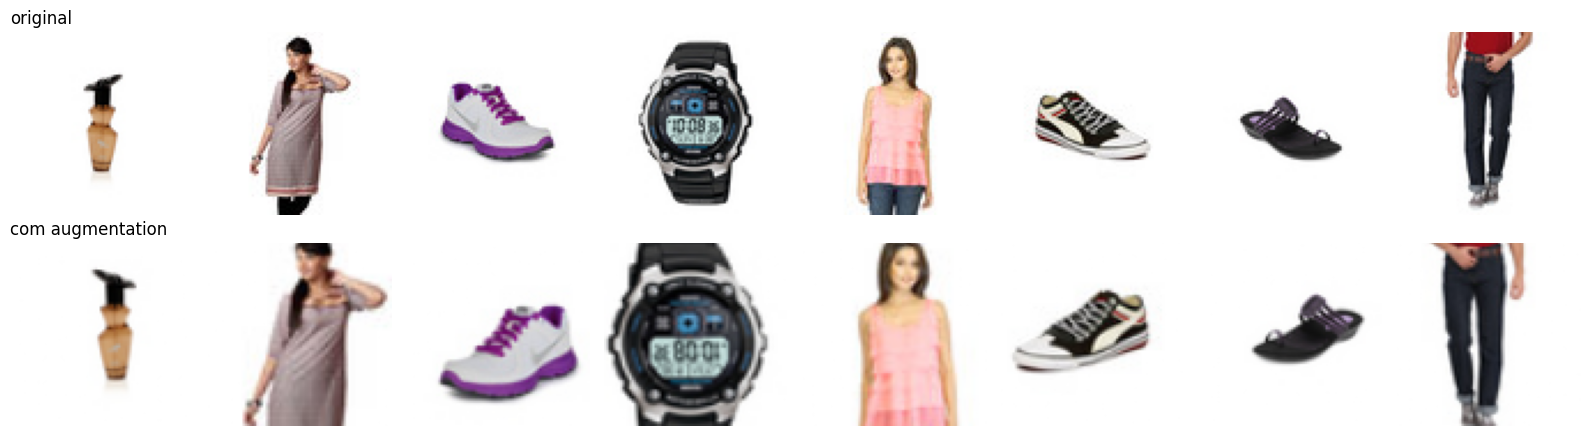

In [ ]:
def random_affine_batch(x):
    b = x.size(0)
    dev = x.device
    scale = torch.empty(b, device=dev).uniform_(0.7, 1.0)
    flip = (torch.rand(b, device=dev) < 0.5).float() * 2 - 1
    tx = torch.empty(b, device=dev).uniform_(-0.1, 0.1) * 2
    ty = torch.empty(b, device=dev).uniform_(-0.1, 0.1) * 2
    theta = torch.zeros(b, 2, 3, device=dev)
    theta[:, 0, 0] = scale * flip
    theta[:, 1, 1] = scale
    theta[:, 0, 2] = tx
    theta[:, 1, 2] = ty
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="border", align_corners=False)


def prepare_batch(xb, train, mean, std, size=IMAGE_SIZE):
    x = xb.float() / 255
    if train:
        x = random_affine_batch(x)
    if size != x.size(-1):
        x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False)
    m = torch.tensor(mean, device=x.device).view(1, 3, 1, 1)
    s = torch.tensor(std, device=x.device).view(1, 3, 1, 1)
    return (x - m) / s


preview = X_train[:8]
aug_preview = random_affine_batch(preview.float() / 255).clamp(0, 1)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i in range(8):
    axes[0, i].imshow(preview[i].permute(1, 2, 0).cpu().numpy())
    axes[1, i].imshow(aug_preview[i].permute(1, 2, 0).cpu().numpy())
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_title("original", loc="left")
axes[1, 0].set_title("com augmentation", loc="left")
plt.tight_layout()
plt.show()

## 3. Vision Transformer implementado do zero

Os blocos abaixo seguem o ViT original (Dosovitskiy et al., 2021):

- **`PatchEmbedding`**: divide a imagem em patches não sobrepostos e projeta cada um para um vetor de dimensão `dim`. Uma `Conv2d` com `kernel_size = stride = patch_size` é equivalente a achatar cada patch e aplicar uma camada linear.
- **`ScaledDotProductAttention`**: calcula $\mathrm{softmax}(QK^\top/\sqrt{d_k})\,V$.
- **`AttentionHead`**: projeções lineares independentes de Q, K e V e uma atenção.
- **`MultiHeadAttention`**: várias cabeças independentes, concatenadas e projetadas de volta para `dim`.
- **`TransformerEncoderBlock`**: LayerNorm *pre-norm*, atenção multi-cabeça e MLP (`dim → 4·dim → dim`, GELU), cada um com conexão residual e *stochastic depth* (`DropPath`).
- **`VisionTransformer`**: patches + token `[CLS]` + embedding posicional aprendível, pilha de blocos, LayerNorm final e classificador linear sobre o `[CLS]`.

In [ ]:
class ScaledDotProductAttention(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

    def forward(self, q, k, v):
        scores = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))
        weights = torch.softmax(scores, dim=-1)
        return self.dropout(weights) @ v, weights


class AttentionHead(nn.Module):
    def __init__(self, dim, head_dim, dropout=0.0):
        super().__init__()
        self.q = nn.Linear(dim, head_dim)
        self.k = nn.Linear(dim, head_dim)
        self.v = nn.Linear(dim, head_dim)
        self.attention = ScaledDotProductAttention(dropout)

    def forward(self, x):
        return self.attention(self.q(x), self.k(x), self.v(x))


class MultiHeadAttention(nn.Module):
    def __init__(self, dim, num_heads, dropout=0.0):
        super().__init__()
        assert dim % num_heads == 0
        self.heads = nn.ModuleList([AttentionHead(dim, dim // num_heads, dropout) for _ in range(num_heads)])
        self.proj = nn.Linear(dim, dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, return_attention=False):
        outputs, weights = [], []
        for head in self.heads:
            out, w = head(x)
            outputs.append(out)
            weights.append(w)
        out = self.dropout(self.proj(torch.cat(outputs, dim=-1)))
        if return_attention:
            return out, torch.stack(weights, dim=1)
        return out


class DropPath(nn.Module):
    def __init__(self, p=0.0):
        super().__init__()
        self.p = p

    def forward(self, x):
        if not self.training or self.p == 0.0:
            return x
        keep = 1.0 - self.p
        mask = x.new_empty(x.size(0), *([1] * (x.dim() - 1))).bernoulli_(keep)
        return x * mask / keep


class TransformerEncoderBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio=4, dropout=0.0, drop_path=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attention = MultiHeadAttention(dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim * mlp_ratio, dim),
            nn.Dropout(dropout),
        )
        self.drop_path = DropPath(drop_path)

    def forward(self, x, return_attention=False):
        if return_attention:
            attn_out, weights = self.attention(self.norm1(x), return_attention=True)
        else:
            attn_out = self.attention(self.norm1(x))
        x = x + self.drop_path(attn_out)
        x = x + self.drop_path(self.mlp(self.norm2(x)))
        if return_attention:
            return x, weights
        return x


class PatchEmbedding(nn.Module):
    def __init__(self, image_size, patch_size, in_channels, dim):
        super().__init__()
        assert image_size % patch_size == 0
        self.num_patches = (image_size // patch_size) ** 2
        self.projection = nn.Conv2d(in_channels, dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        return self.projection(x).flatten(2).transpose(1, 2)


class VisionTransformer(nn.Module):
    def __init__(self, image_size=80, patch_size=8, in_channels=3, num_classes=20,
                 dim=192, depth=6, num_heads=3, mlp_ratio=4, dropout=0.1, drop_path=0.1):
        super().__init__()
        self.patch_embedding = PatchEmbedding(image_size, patch_size, in_channels, dim)
        num_tokens = self.patch_embedding.num_patches + 1
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_tokens, dim))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        self.dropout = nn.Dropout(dropout)
        rates = torch.linspace(0, drop_path, depth).tolist()
        self.blocks = nn.ModuleList([
            TransformerEncoderBlock(dim, num_heads, mlp_ratio, dropout, rates[i]) for i in range(depth)
        ])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

    def embed(self, x):
        tokens = self.patch_embedding(x)
        cls = self.cls_token.expand(tokens.size(0), -1, -1)
        return torch.cat([cls, tokens], dim=1)

    def forward(self, x, return_attention=False):
        x = self.dropout(self.embed(x) + self.pos_embed)
        attentions = []
        for block in self.blocks:
            if return_attention:
                x, w = block(x, return_attention=True)
                attentions.append(w)
            else:
                x = block(x)
        logits = self.head(self.norm(x)[:, 0])
        if return_attention:
            return logits, attentions
        return logits


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


vit_scratch_config = dict(image_size=80, patch_size=8, dim=192, depth=6, num_heads=3, dropout=0.1, drop_path=0.1)
print(f"Parâmetros do ViT do zero: {count_parameters(VisionTransformer(num_classes=NUM_CLASSES, **vit_scratch_config)):,}")

Parâmetros do ViT do zero: 2,730,068


### Testes unitários dos componentes

Cada teste verifica uma propriedade matemática do componente implementado:
1. a atenção própria coincide com `F.scaled_dot_product_attention` do PyTorch;
2. cada linha da matriz de atenção soma 1 (softmax);
3. as cabeças são independentes (alterar os pesos de uma não muda a atenção das outras);
4. com os pesos de saída zerados, o bloco encoder se reduz à identidade (conexões residuais);
5. sem embedding posicional o `[CLS]` é invariante à ordem dos patches; com embedding posicional deixa de ser.

In [ ]:
torch.manual_seed(0)
cpu = torch.device("cpu")

q = torch.randn(2, 5, 8)
k = torch.randn(2, 5, 8)
v = torch.randn(2, 5, 8)
out, w = ScaledDotProductAttention()(q, k, v)
assert torch.allclose(out, F.scaled_dot_product_attention(q, k, v), atol=1e-5)
assert torch.allclose(w.sum(-1), torch.ones(2, 5), atol=1e-5)
print("1-2. Atenção coincide com a referência do PyTorch e as linhas somam 1: OK")

mha = MultiHeadAttention(dim=24, num_heads=3).eval()
x = torch.randn(2, 7, 24)
_, w_before = mha(x, return_attention=True)
with torch.no_grad():
    mha.heads[0].q.weight.add_(1.0)
_, w_after = mha(x, return_attention=True)
assert w_before.shape == (2, 3, 7, 7)
assert not torch.allclose(w_before[:, 0], w_after[:, 0])
assert torch.allclose(w_before[:, 1:], w_after[:, 1:])
print("3. Cabeças de atenção independentes: OK")

block = TransformerEncoderBlock(dim=24, num_heads=3).eval()
with torch.no_grad():
    block.attention.proj.weight.zero_()
    block.attention.proj.bias.zero_()
    block.mlp[3].weight.zero_()
    block.mlp[3].bias.zero_()
x = torch.randn(2, 7, 24)
assert torch.allclose(block(x), x, atol=1e-6)
print("4. Bloco com saídas zeradas = identidade (residual): OK")

tiny = VisionTransformer(image_size=32, patch_size=8, dim=48, depth=2, num_heads=3, dropout=0.0, drop_path=0.0).eval()
tokens = tiny.patch_embedding(torch.randn(1, 3, 32, 32))
perm = torch.randperm(tokens.size(1))


def cls_output(model, tokens, pos):
    x = torch.cat([model.cls_token.expand(tokens.size(0), -1, -1), tokens], dim=1) + pos
    for blk in model.blocks:
        x = blk(x)
    return model.norm(x)[:, 0]


with torch.no_grad():
    zero_pos = torch.zeros_like(tiny.pos_embed)
    rand_pos = torch.randn_like(tiny.pos_embed)
    same = torch.allclose(cls_output(tiny, tokens, zero_pos), cls_output(tiny, tokens[:, perm], zero_pos), atol=1e-5)
    different = not torch.allclose(cls_output(tiny, tokens, rand_pos), cls_output(tiny, tokens[:, perm], rand_pos), atol=1e-5)
assert same and different
print("5. Invariância à permutação sem PE e dependência de ordem com PE: OK")

logits = VisionTransformer(num_classes=NUM_CLASSES, **vit_scratch_config).eval()(torch.randn(4, 3, 80, 80))
assert logits.shape == (4, NUM_CLASSES)
print(f"Forma da saída do ViT completo: {tuple(logits.shape)}")

1-2. Atenção coincide com a referência do PyTorch e as linhas somam 1: OK
3. Cabeças de atenção independentes: OK
4. Bloco com saídas zeradas = identidade (residual): OK
5. Invariância à permutação sem PE e dependência de ordem com PE: OK
Forma da saída do ViT completo: (4, 20)


## 4. Funções de treino e avaliação

O treinamento usa:
- **AdamW** com *weight decay* aplicado apenas a pesos de matrizes (sem decay em bias, LayerNorm, `[CLS]` e embedding posicional);
- **warmup linear + decaimento cosseno** do *learning rate*, atualizado a cada passo;
- **precisão mista (fp16)** com `GradScaler`, adequada à T4;
- **gradient clipping** em 1,0 e **label smoothing**;
- seleção do **melhor checkpoint pela acurácia de validação**.

In [ ]:
def build_optimizer(model, lr, weight_decay):
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if p.ndim <= 1 or "cls_token" in name or "pos_embed" in name or "position_embeddings" in name:
            no_decay.append(p)
        else:
            decay.append(p)
    return torch.optim.AdamW(
        [{"params": decay, "weight_decay": weight_decay}, {"params": no_decay, "weight_decay": 0.0}],
        lr=lr,
    )


def evaluate(model, X, y, mean, std, size=IMAGE_SIZE, batch_size=256):
    model.eval()
    losses, preds = [], []
    with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
        for i in range(0, len(X), batch_size):
            xb = prepare_batch(X[i:i + batch_size], False, mean, std, size)
            logits = model(xb)
            losses.append(F.cross_entropy(logits.float(), y[i:i + batch_size], reduction="sum").item())
            preds.append(logits.argmax(1))
    preds = torch.cat(preds)
    return sum(losses) / len(X), (preds == y).float().mean().item(), preds.cpu().numpy()


def train_model(model, epochs, lr, weight_decay, batch_size, warmup_epochs, label_smoothing, mean, std, size=IMAGE_SIZE):
    model.to(device)
    optimizer = build_optimizer(model, lr, weight_decay)
    steps_per_epoch = math.ceil(len(X_train) / batch_size)
    total_steps = epochs * steps_per_epoch
    warmup_steps = warmup_epochs * steps_per_epoch

    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_epoch, best_state = -1.0, 0, None
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(X_train), device=device)
        running_loss, running_correct = 0.0, 0
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            xb = prepare_batch(X_train[idx], True, mean, std, size)
            yb = y_train[idx]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
                logits = model(xb)
                loss = F.cross_entropy(logits.float(), yb, label_smoothing=label_smoothing)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running_loss += loss.item() * len(idx)
            running_correct += (logits.argmax(1) == yb).sum().item()

        val_loss, val_acc, _ = evaluate(model, X_val, y_val, mean, std, size)
        history["train_loss"].append(running_loss / len(X_train))
        history["train_acc"].append(running_correct / len(X_train))
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(f"Época {epoch:3d}/{epochs} | loss {history['train_loss'][-1]:.4f} | acc {history['train_acc'][-1]:.4f} "
                  f"| val_loss {val_loss:.4f} | val_acc {val_acc:.4f} | {time.time() - start:.0f}s")

    elapsed = time.time() - start
    model.load_state_dict(best_state)
    return history, best_epoch, elapsed


def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], label="treino")
    axes[0].plot(epochs, history["val_loss"], label="validação")
    axes[0].set_title(f"{title} — perda")
    axes[0].set_xlabel("época")
    axes[0].legend()
    axes[1].plot(epochs, history["train_acc"], label="treino")
    axes[1].plot(epochs, history["val_acc"], label="validação")
    axes[1].set_title(f"{title} — acurácia")
    axes[1].set_xlabel("época")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


results = {}

## 5. Experimento 1 — ViT treinado do zero

Configuração: patches 8×8 (100 patches + `[CLS]`), `dim=192`, 6 camadas, 3 cabeças, MLP 4×, dropout 0,1 e *drop path* até 0,1. Treino por 60 épocas, batch 128, `lr=5e-4`, `weight_decay=0,05`, 5 épocas de warmup e *label smoothing* 0,1. Como o ViT não tem o viés indutivo de localidade das CNNs, ele depende de mais épocas e de augmentation/regularização para generalizar com poucos dados.

/tmp/ipykernel_1952/1781823223.py:43: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")


Época   1/60 | loss 2.7578 | acc 0.1595 | val_loss 2.5350 | val_acc 0.1693 | 15s
Época   5/60 | loss 1.6719 | acc 0.5512 | val_loss 1.2663 | val_acc 0.5841 | 57s
Época  10/60 | loss 1.3739 | acc 0.6763 | val_loss 1.0905 | val_acc 0.6501 | 93s
Época  15/60 | loss 1.2566 | acc 0.7195 | val_loss 0.8129 | val_acc 0.7330 | 131s
Época  20/60 | loss 1.1597 | acc 0.7673 | val_loss 0.7327 | val_acc 0.7602 | 171s
Época  25/60 | loss 1.1157 | acc 0.7781 | val_loss 0.6471 | val_acc 0.7937 | 209s
Época  30/60 | loss 1.0589 | acc 0.7998 | val_loss 0.6131 | val_acc 0.8103 | 249s
Época  35/60 | loss 1.0172 | acc 0.8195 | val_loss 0.5819 | val_acc 0.8167 | 286s
Época  40/60 | loss 0.9755 | acc 0.8354 | val_loss 0.5760 | val_acc 0.8201 | 326s
Época  45/60 | loss 0.9413 | acc 0.8517 | val_loss 0.5298 | val_acc 0.8311 | 364s
Época  50/60 | loss 0.9112 | acc 0.8642 | val_loss 0.5151 | val_acc 0.8428 | 402s
Época  55/60 | loss 0.8980 | acc 0.8689 | val_loss 0.4848 | val_acc 0.8578 | 440s
Época  60/60 | loss

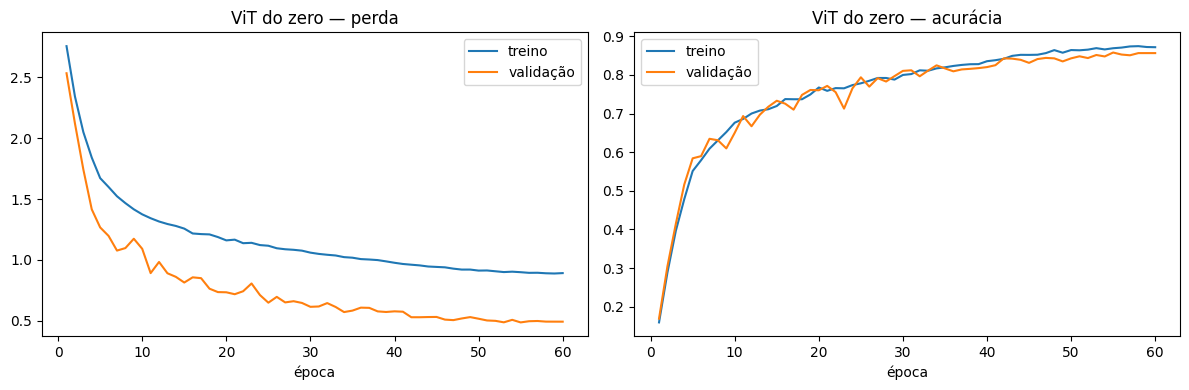

In [ ]:
torch.manual_seed(SEED)
vit_scratch = VisionTransformer(num_classes=NUM_CLASSES, **vit_scratch_config)

hist_scratch, best_ep_scratch, time_scratch = train_model(
    vit_scratch, epochs=60, lr=5e-4, weight_decay=0.05, batch_size=128,
    warmup_epochs=5, label_smoothing=0.1, mean=MEAN_LOCAL, std=STD_LOCAL,
)
results["ViT do zero"] = dict(model=vit_scratch, history=hist_scratch, best_epoch=best_ep_scratch,
                              train_time=time_scratch, mean=MEAN_LOCAL, std=STD_LOCAL, size=IMAGE_SIZE)
print(f"Melhor época: {best_ep_scratch} | tempo de treino: {time_scratch / 60:.1f} min")
plot_history(hist_scratch, "ViT do zero")

## 6. Experimento 2 — ViT-B/16 pré-treinado (fine-tuning)

Usa `google/vit-base-patch16-224-in21k` (ViT-Base, patches 16×16, pré-treinado no ImageNet-21k). A cabeça de classificação é substituída por uma camada linear nova com 20 saídas e **todos os pesos** são ajustados (fine-tuning completo) com *learning rate* baixo (`5e-5`) por 4 épocas. As imagens são redimensionadas para 224×224 e normalizadas com as estatísticas do `AutoImageProcessor` do modelo.

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_1952/1781823223.py:43: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")


Parâmetros do ViT-B/16: 85,814,036
Época   1/4 | loss 2.1637 | acc 0.6609 | val_loss 0.9246 | val_acc 0.9140 | 112s
Época   4/4 | loss 0.6987 | acc 0.9707 | val_loss 0.3422 | val_acc 0.9476 | 445s
Melhor época: 4 | tempo de treino: 7.4 min


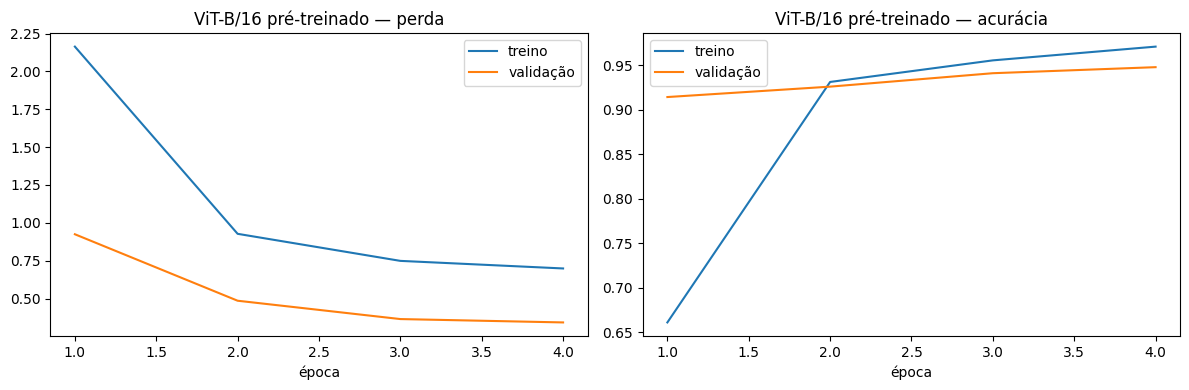

In [ ]:
HF_NAME = "google/vit-base-patch16-224-in21k"
processor = AutoImageProcessor.from_pretrained(HF_NAME)
HF_MEAN, HF_STD = list(processor.image_mean), list(processor.image_std)


class HFViT(nn.Module):
    def __init__(self, attn_implementation=None):
        super().__init__()
        kwargs = {"attn_implementation": attn_implementation} if attn_implementation else {}
        self.model = ViTForImageClassification.from_pretrained(HF_NAME, num_labels=NUM_CLASSES, **kwargs)

    def forward(self, x):
        return self.model(pixel_values=x).logits


torch.manual_seed(SEED)
vit_pretrained = HFViT()
print(f"Parâmetros do ViT-B/16: {count_parameters(vit_pretrained):,}")

hist_pre, best_ep_pre, time_pre = train_model(
    vit_pretrained, epochs=4, lr=5e-5, weight_decay=0.05, batch_size=64,
    warmup_epochs=1, label_smoothing=0.1, mean=HF_MEAN, std=HF_STD, size=224,
)
results["ViT-B/16 pré-treinado"] = dict(model=vit_pretrained, history=hist_pre, best_epoch=best_ep_pre,
                                         train_time=time_pre, mean=HF_MEAN, std=HF_STD, size=224)
print(f"Melhor época: {best_ep_pre} | tempo de treino: {time_pre / 60:.1f} min")
plot_history(hist_pre, "ViT-B/16 pré-treinado")

## 7. Experimento 3 — CNN pré-treinada (ResNet-18)

Baseline convolucional: ResNet-18 com pesos do ImageNet (`IMAGENET1K_V1`), cabeça substituída por `Linear(512, 20)` e fine-tuning completo por 8 épocas (`lr=5e-4`, entrada 112×112, normalização ImageNet). Serve de referência de uma arquitetura com viés indutivo de localidade e compartilhamento de pesos.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 140MB/s]
/tmp/ipykernel_1952/1781823223.py:43: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")


Parâmetros da ResNet-18: 11,186,772
Época   1/8 | loss 1.3401 | acc 0.7383 | val_loss 0.6107 | val_acc 0.8269 | 7s
Época   5/8 | loss 0.7294 | acc 0.9474 | val_loss 0.3235 | val_acc 0.9118 | 31s
Época   8/8 | loss 0.6618 | acc 0.9744 | val_loss 0.2802 | val_acc 0.9329 | 49s
Melhor época: 8 | tempo de treino: 0.8 min


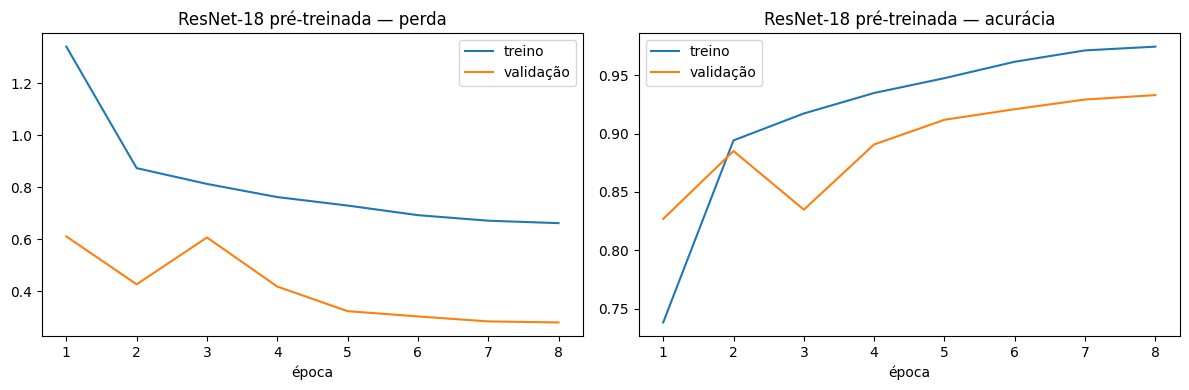

In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

torch.manual_seed(SEED)
resnet = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
resnet.fc = nn.Linear(resnet.fc.in_features, NUM_CLASSES)
print(f"Parâmetros da ResNet-18: {count_parameters(resnet):,}")

hist_cnn, best_ep_cnn, time_cnn = train_model(
    resnet, epochs=8, lr=5e-4, weight_decay=0.05, batch_size=128,
    warmup_epochs=1, label_smoothing=0.1, mean=IMAGENET_MEAN, std=IMAGENET_STD, size=112,
)
results["ResNet-18 pré-treinada"] = dict(model=resnet, history=hist_cnn, best_epoch=best_ep_cnn,
                                          train_time=time_cnn, mean=IMAGENET_MEAN, std=IMAGENET_STD, size=112)
print(f"Melhor época: {best_ep_cnn} | tempo de treino: {time_cnn / 60:.1f} min")
plot_history(hist_cnn, "ResNet-18 pré-treinada")

## 8. Comparação dos resultados

Todos os modelos são avaliados no **conjunto de teste**, que não participou do treino nem da escolha de checkpoint. Além da acurácia, são reportados o intervalo de confiança de 95% (aproximação normal da proporção), o F1 macro (que dá o mesmo peso a todas as classes) e a velocidade de inferência.

In [ ]:
y_test_np = y_test.cpu().numpy()
rows = []
for name, r in results.items():
    model = r["model"]
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    _, _, preds_val = evaluate(model, X_val, y_val, r["mean"], r["std"], r["size"])
    _, test_acc, preds = evaluate(model, X_test, y_test, r["mean"], r["std"], r["size"])
    if device.type == "cuda":
        torch.cuda.synchronize()
    infer_time = time.time() - t0
    r["test_preds"] = preds
    n = len(y_test_np)
    ci = 1.96 * math.sqrt(test_acc * (1 - test_acc) / n)
    rows.append({
        "Modelo": name,
        "Parâmetros (M)": count_parameters(model) / 1e6,
        "Tempo de treino (min)": r["train_time"] / 60,
        "Melhor época": r["best_epoch"],
        "Acurácia val.": max(r["history"]["val_acc"]),
        "Acurácia teste": test_acc,
        "IC 95% (±)": ci,
        "F1 macro teste": f1_score(y_test_np, preds, average="macro"),
        "Inferência (img/s)": (len(X_val) + len(X_test)) / infer_time,
    })

comparison = pd.DataFrame(rows).set_index("Modelo")
comparison.style.format({
    "Parâmetros (M)": "{:.1f}", "Tempo de treino (min)": "{:.1f}", "Acurácia val.": "{:.4f}",
    "Acurácia teste": "{:.4f}", "IC 95% (±)": "{:.4f}", "F1 macro teste": "{:.4f}", "Inferência (img/s)": "{:.0f}",
})

,Parâmetros (M),Tempo de treino (min),Melhor época,Acurácia val.,Acurácia teste,IC 95% (±),F1 macro teste,Inferência (img/s)
Modelo,,,,,,,,
ViT do zero,2.7,8.0,55,0.8578,0.8363,0.0141,0.8419,6613
ViT-B/16 pré-treinado,85.8,7.4,4,0.9476,0.9438,0.0088,0.9472,366
ResNet-18 pré-treinada,11.2,0.8,8,0.9329,0.9280,0.0098,0.9317,7781


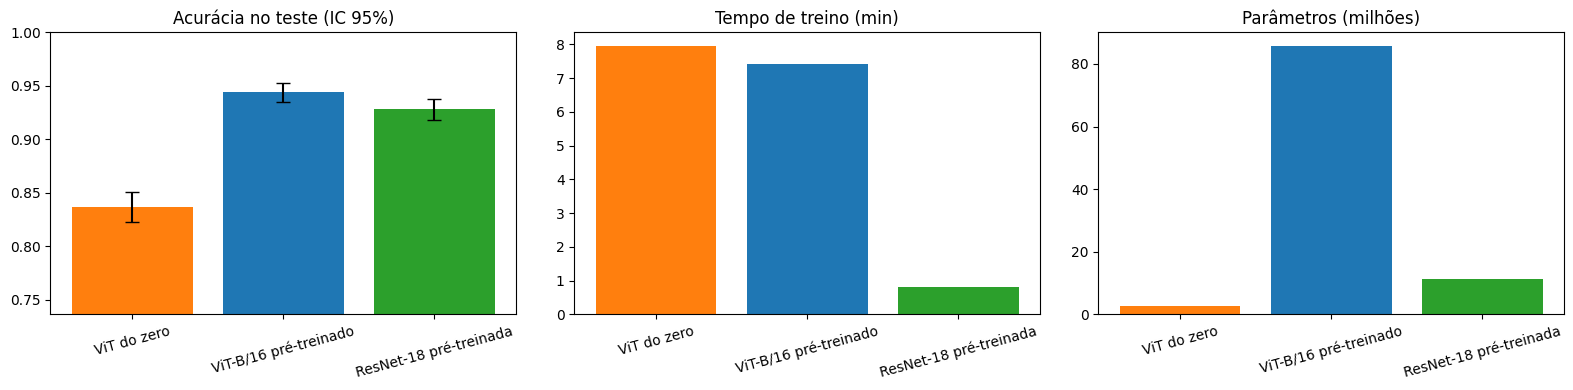

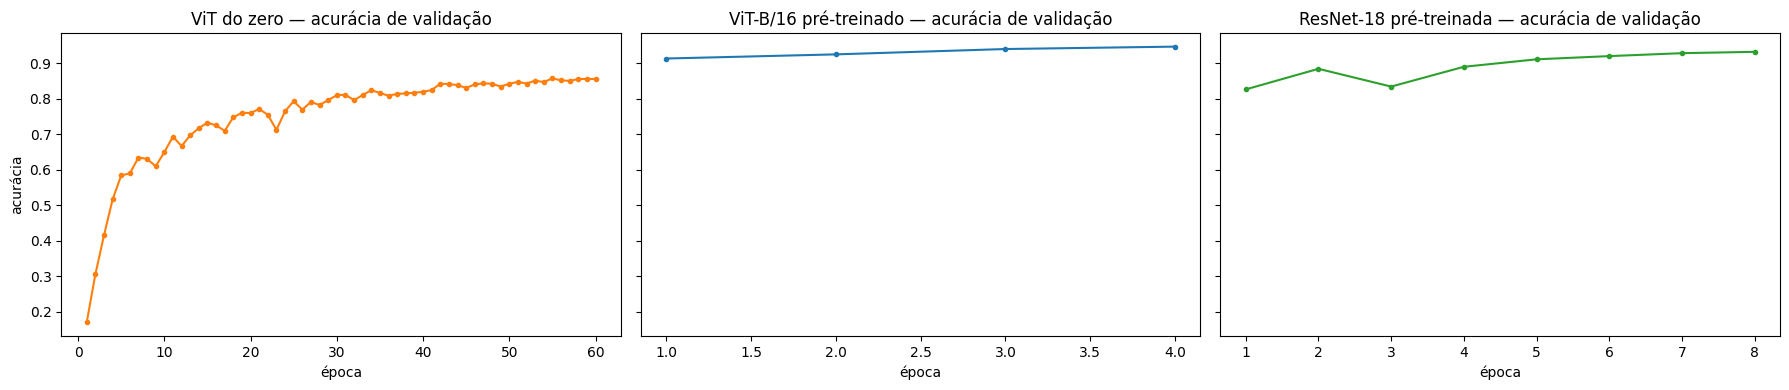

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
names = list(results.keys())
colors = ["tab:orange", "tab:blue", "tab:green"]

axes[0].bar(names, comparison["Acurácia teste"], yerr=comparison["IC 95% (±)"], color=colors, capsize=5)
axes[0].set_ylim(comparison["Acurácia teste"].min() - 0.1, 1.0)
axes[0].set_title("Acurácia no teste (IC 95%)")
axes[1].bar(names, comparison["Tempo de treino (min)"], color=colors)
axes[1].set_title("Tempo de treino (min)")
axes[2].bar(names, comparison["Parâmetros (M)"], color=colors)
axes[2].set_title("Parâmetros (milhões)")
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, (name, r), c in zip(axes, results.items(), colors):
    ax.plot(range(1, len(r["history"]["val_acc"]) + 1), r["history"]["val_acc"], color=c, marker="o", markersize=3)
    ax.set_title(f"{name} — acurácia de validação")
    ax.set_xlabel("época")
axes[0].set_ylabel("acurácia")
plt.tight_layout()
plt.show()

### F1 por classe e matrizes de confusão

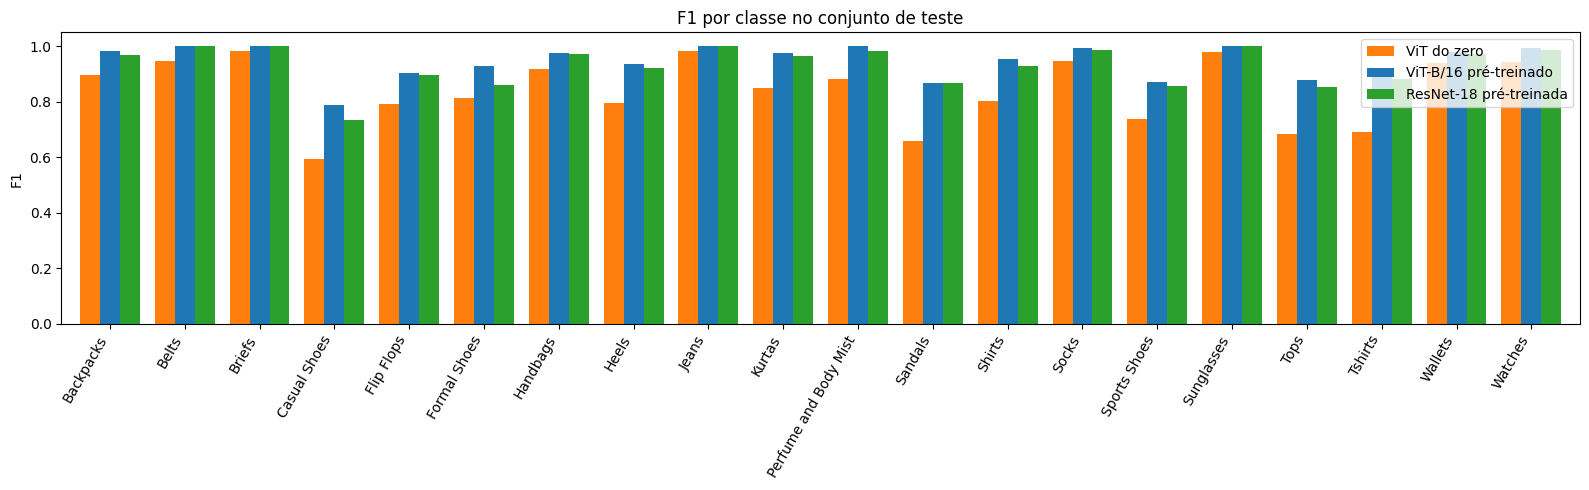

,ViT do zero,ViT-B/16 pré-treinado,ResNet-18 pré-treinada
Backpacks,0.896,0.982,0.968
Belts,0.947,1.000,1.000
Briefs,0.984,1.000,1.000
Casual Shoes,0.593,0.787,0.735
Flip Flops,0.793,0.903,0.895
Formal Shoes,0.813,0.928,0.862
Handbags,0.918,0.977,0.974
Heels,0.796,0.934,0.921
Jeans,0.984,1.000,1.000
Kurtas,0.848,0.974,0.966


In [ ]:
from sklearn.metrics import precision_recall_fscore_support

per_class = pd.DataFrame(index=CLASS_NAMES)
for name, r in results.items():
    _, _, f1, _ = precision_recall_fscore_support(y_test_np, r["test_preds"], labels=range(NUM_CLASSES), zero_division=0)
    per_class[name] = f1

per_class.plot.bar(figsize=(16, 5), color=colors, width=0.8)
plt.ylabel("F1")
plt.title("F1 por classe no conjunto de teste")
plt.ylim(0, 1.05)
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

per_class.style.format("{:.3f}").background_gradient(cmap="RdYlGn", axis=None, vmin=0.4, vmax=1.0)

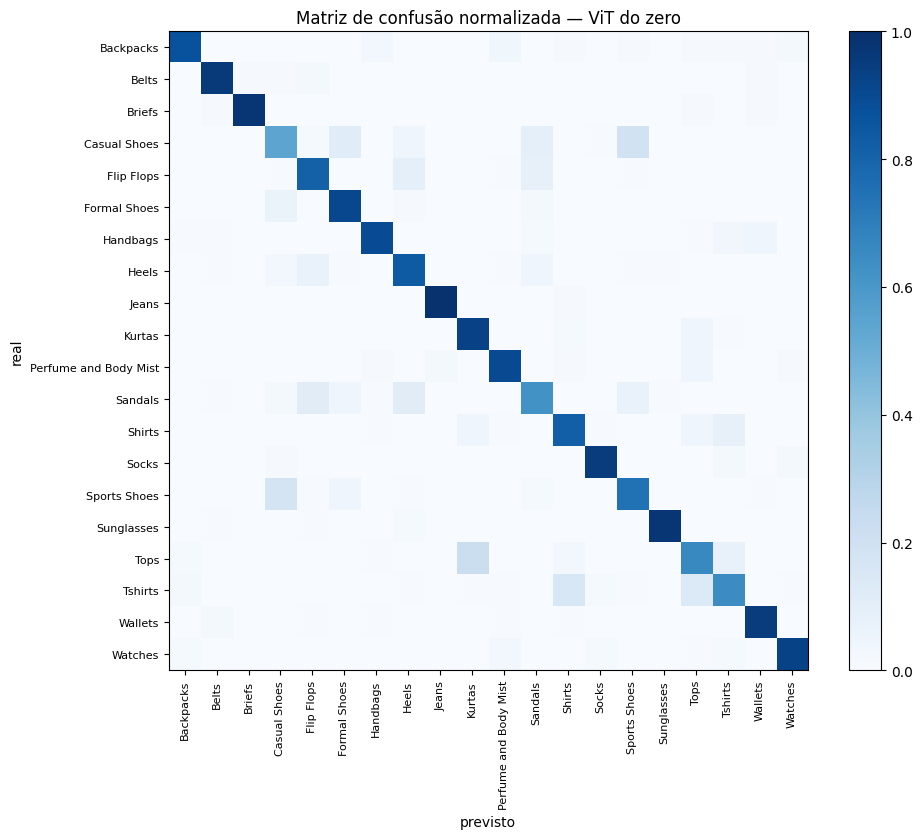

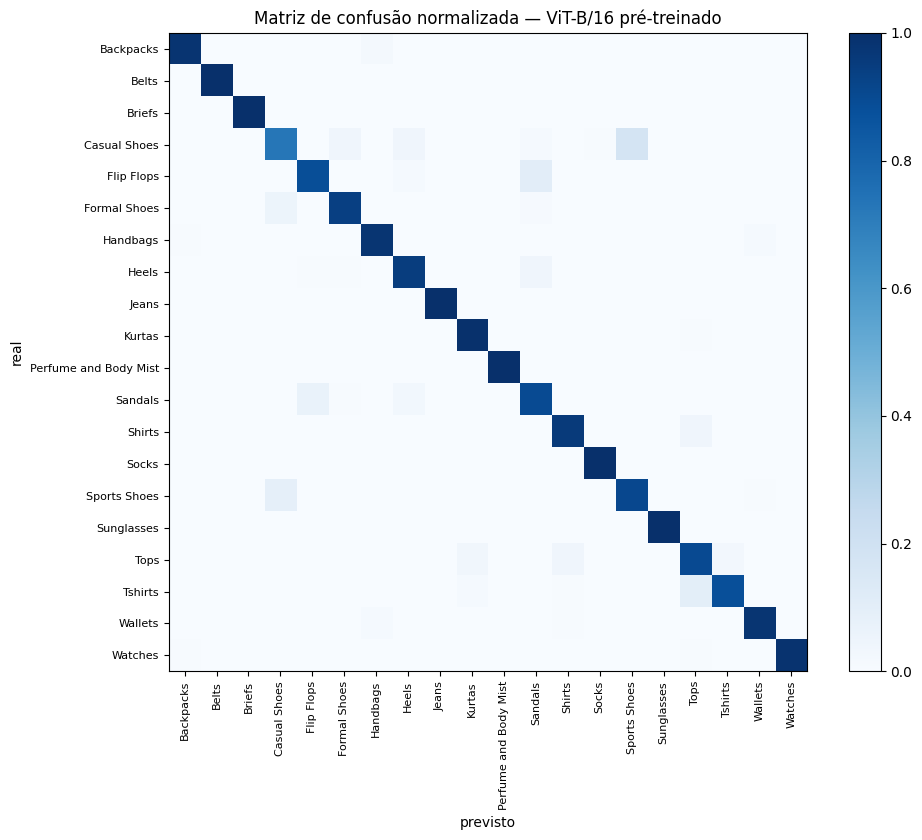

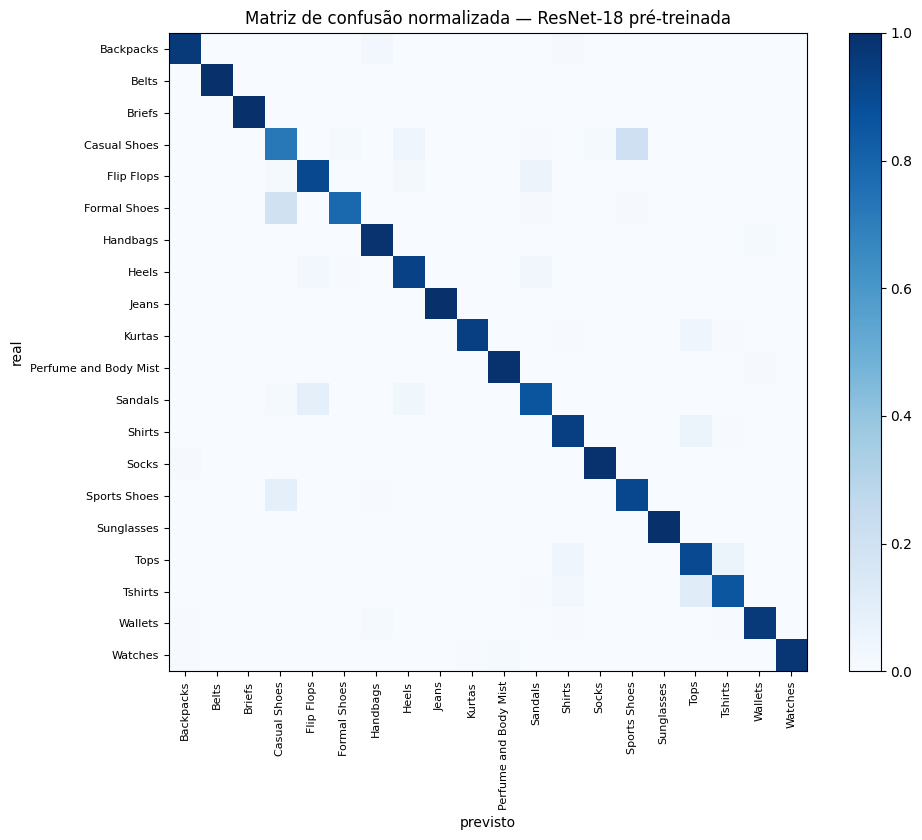

In [ ]:
for name, r in results.items():
    cm = confusion_matrix(y_test_np, r["test_preds"], labels=range(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(10, 8.5))
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=8)
    ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_xlabel("previsto")
    ax.set_ylabel("real")
    ax.set_title(f"Matriz de confusão normalizada — {name}")
    plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()

In [ ]:
def top_confusions(preds, k=8):
    cm = confusion_matrix(y_test_np, preds, labels=range(NUM_CLASSES))
    totals = cm.sum(axis=1)
    pairs = []
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if i != j and cm[i, j] > 0:
                pairs.append((CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j]), cm[i, j] / totals[i]))
    pairs.sort(key=lambda t: -t[2])
    return pd.DataFrame(pairs[:k], columns=["classe real", "prevista como", "erros", "% da classe real"])


for name, r in results.items():
    print(f"Maiores confusões — {name}")
    display(top_confusions(r["test_preds"]).style.format({"% da classe real": "{:.1%}"}).hide(axis="index"))

Maiores confusões — ViT do zero


classe real,prevista como,erros,% da classe real
Tops,Kurtas,33,22.0%
Casual Shoes,Sports Shoes,29,19.3%
Sports Shoes,Casual Shoes,26,17.3%
Tshirts,Shirts,23,15.3%
Tshirts,Tops,20,13.3%
Casual Shoes,Formal Shoes,17,11.3%
Sandals,Flip Flops,15,11.1%
Sandals,Heels,15,11.1%


Maiores confusões — ViT-B/16 pré-treinado


classe real,prevista como,erros,% da classe real
Casual Shoes,Sports Shoes,26,17.3%
Tshirts,Tops,15,10.0%
Flip Flops,Sandals,14,10.2%
Sports Shoes,Casual Shoes,13,8.7%
Sandals,Flip Flops,9,6.7%
Casual Shoes,Formal Shoes,6,4.0%
Casual Shoes,Heels,6,4.0%
Heels,Sandals,6,4.0%


Maiores confusões — ResNet-18 pré-treinada


classe real,prevista como,erros,% da classe real
Casual Shoes,Sports Shoes,31,20.7%
Formal Shoes,Casual Shoes,19,19.8%
Tshirts,Tops,17,11.3%
Sports Shoes,Casual Shoes,13,8.7%
Sandals,Flip Flops,12,8.9%
Tops,Tshirts,9,6.0%
Flip Flops,Sandals,8,5.8%
Shirts,Tops,8,5.3%


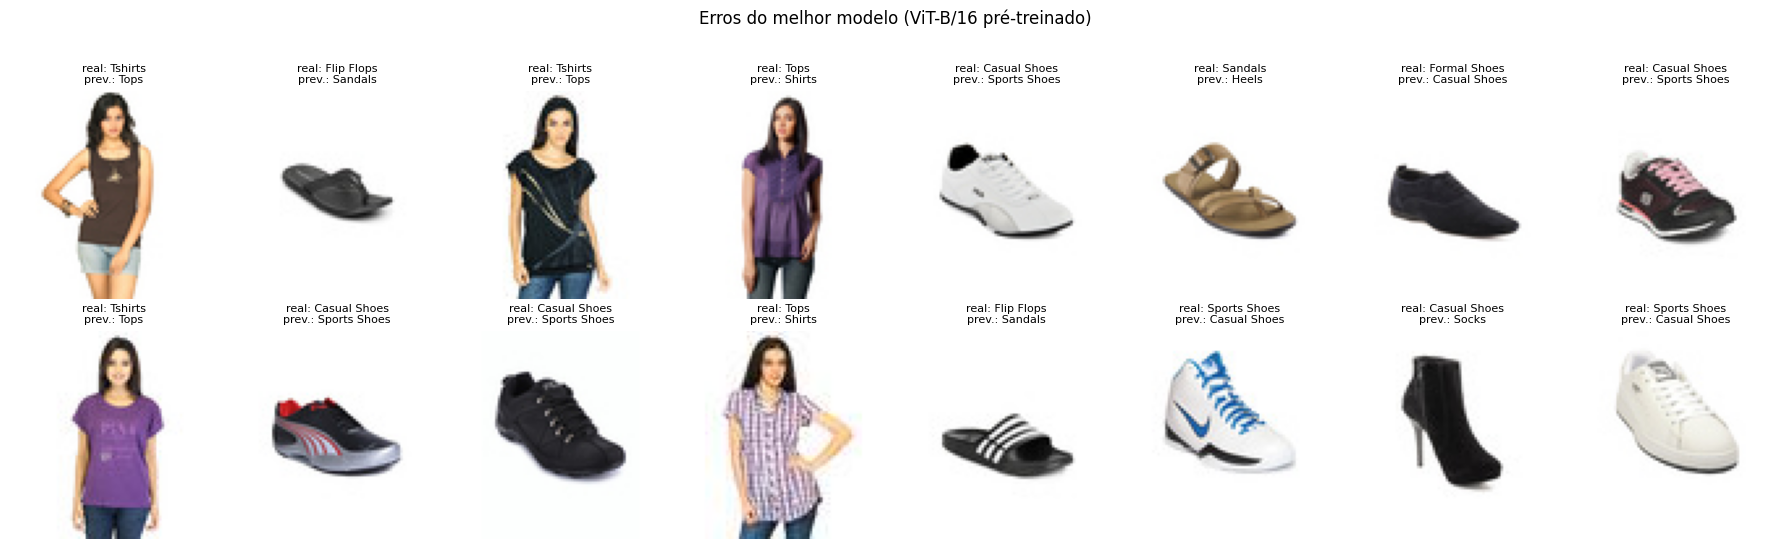

In [ ]:
best_name = comparison["Acurácia teste"].idxmax()
best = results[best_name]
wrong = np.where(best["test_preds"] != y_test_np)[0]
rng = np.random.RandomState(SEED)
sample = rng.choice(wrong, size=min(16, len(wrong)), replace=False)

fig, axes = plt.subplots(2, 8, figsize=(18, 5.5))
for ax, i in zip(axes.flat, sample):
    ax.imshow(X_test[i].permute(1, 2, 0).cpu().numpy())
    ax.set_title(f"real: {CLASS_NAMES[y_test_np[i]]}\nprev.: {CLASS_NAMES[best['test_preds'][i]]}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Erros do melhor modelo ({best_name})", y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
best_acc_name = comparison["Acurácia teste"].idxmax()
scratch_acc = comparison.loc["ViT do zero", "Acurácia teste"]
pre_acc = comparison.loc["ViT-B/16 pré-treinado", "Acurácia teste"]
cnn_acc = comparison.loc["ResNet-18 pré-treinada", "Acurácia teste"]
worst_class = per_class["ViT do zero"].idxmin()

print(f"Melhor modelo no teste: {best_acc_name} ({comparison.loc[best_acc_name, 'Acurácia teste']:.2%})")
print(f"ViT pré-treinado vs ViT do zero: {100 * (pre_acc - scratch_acc):+.2f} p.p.")
print(f"ViT do zero vs ResNet-18: {100 * (scratch_acc - cnn_acc):+.2f} p.p.")
print(f"Tempo de treino: ViT do zero {time_scratch / 60:.1f} min | ViT-B/16 {time_pre / 60:.1f} min | ResNet-18 {time_cnn / 60:.1f} min")
print(f"Classe mais difícil para o ViT do zero: {worst_class} (F1 = {per_class.loc[worst_class, 'ViT do zero']:.3f})")

Melhor modelo no teste: ViT-B/16 pré-treinado (94.38%)
ViT pré-treinado vs ViT do zero: +10.75 p.p.
ViT do zero vs ResNet-18: -9.16 p.p.
Tempo de treino: ViT do zero 8.0 min | ViT-B/16 7.4 min | ResNet-18 0.8 min
Classe mais difícil para o ViT do zero: Casual Shoes (F1 = 0.593)


### Análise dos resultados

| Modelo | Parâmetros | Treino | Acurácia no teste (IC 95%) | F1 macro |
|---|---|---|---|---|
| ViT do zero | 2,7 M | 8,0 min | 83,63% (±1,41) | 0,842 |
| ViT-B/16 pré-treinado | 85,8 M | 7,4 min | **94,38% (±0,88)** | 0,947 |
| ResNet-18 pré-treinada | 11,2 M | 0,8 min | 92,80% (±0,98) | 0,932 |

**Pré-treino é o fator dominante.** O ViT-B/16 supera o ViT do zero em 10,75 p.p., diferença muito maior que os intervalos de confiança. O ViT do zero tem apenas ~12 mil imagens de treino e não possui o viés indutivo de localidade das CNNs; precisou de 60 épocas para chegar a 83,6%, enquanto o ViT-B/16 atingiu 91,4% de acurácia de validação já na primeira época, porque reaproveita representações aprendidas no ImageNet-21k.

**ViT pré-treinado vs. CNN.** A diferença entre ViT-B/16 e ResNet-18 é de 1,58 p.p., e os intervalos de confiança (93,50–95,26% contra 91,82–93,78%) se sobrepõem, então não há evidência estatística firme de que o ViT-B/16 seja melhor. Em contrapartida, o custo é muito diferente: 85,8 M contra 11,2 M de parâmetros, ~9× mais tempo de treino (7,4 contra 0,8 min) e inferência ~21× mais lenta (366 contra 7.781 img/s). Para esta aplicação de varejo, a ResNet-18 entrega praticamente a mesma qualidade por uma fração do custo; o ViT-B/16 compensa se a prioridade for a última fração de acurácia.

**ViT do zero vs. CNN.** O ViT do zero fica 9,16 p.p. abaixo da ResNet-18, mas é o modelo com menos parâmetros (2,7 M) e tem inferência rápida (6.613 img/s). As curvas mostram que ele **não sobreajustou** (acurácia de treino 87,2% contra 85,6% de validação, com perda de validação abaixo da de treino por causa de dropout, *drop path*, *label smoothing* e augmentation ativos só no treino) e que ainda estava melhorando ao final, ou seja, está subajustado e se beneficiaria de mais épocas ou de mais dados. A ResNet-18, ao contrário, mostra uma folga de ~4 p.p. entre treino (97,4%) e validação (93,3%), sinal de início de sobreajuste.

**Análise por classe.** Categorias com forma e contexto muito distintos (Jeans, Briefs, Belts, Sunglasses, Perfume, Watches) têm F1 próximo de 1,0 nos três modelos. O desempenho cai nas classes visualmente ambíguas, e o ViT do zero sofre mais nelas: Casual Shoes (F1 0,593 no ViT do zero; 0,787 no ViT-B/16; 0,735 na ResNet-18), Sandals (0,659), Tshirts (0,690) e Tops (0,683).

**Erros recorrentes** (matrizes de confusão e tabelas de maiores confusões):
- **Calçados:** Casual Shoes ↔ Sports Shoes é a principal confusão nos três modelos (17–21% dos Casual Shoes previstos como Sports Shoes), além de Casual ↔ Formal, Sandals ↔ Flip Flops e Heels ↔ Sandals. A fronteira entre essas classes é semântica (uso, ocasião), não visual, e o rótulo do catálogo é ambíguo.
- **Parte de cima:** Tshirts ↔ Tops ↔ Shirts e, no ViT do zero, Tops → Kurtas (22% dos Tops), confusão que não aparece entre as oito maiores nos modelos pré-treinados. Em imagens de 80×80 px, detalhes como gola, manga e comprimento, que distinguem essas peças, são difíceis de enxergar.
- Parte dos erros reflete **ruído de rotulagem** inerente a um catálogo real (peças que poderiam pertencer a mais de uma categoria), o que limita o teto de acurácia mesmo para o melhor modelo.

**Por que isso importa no varejo.** Os erros dos modelos pré-treinados se concentram em pares de categorias vizinhas dentro da mesma família de produto (calçados, camisetas), o que é menos grave para busca e recomendação do que uma troca entre famílias diferentes (por exemplo, relógio × bolsa). Uma melhoria prática seria usar resolução maior e metadados de catálogo (gênero, subcategoria) como informação complementar.

## 9. Visualização da atenção

A atenção é inspecionada de três formas:
1. **Matriz de atenção por cabeça** (última camada do ViT do zero): cada linha mostra, para um token de consulta, quanto ele atende a cada token; a linha 0 é o `[CLS]`.
2. **Atenção do `[CLS]` para os patches**, por cabeça, redimensionada para a grade 10×10 e sobreposta à imagem.
3. **Attention rollout** (Abnar & Zuidema, 2020): propaga a atenção através de todas as camadas, somando a conexão residual (`0,5·A + 0,5·I`, linhas renormalizadas) e multiplicando as matrizes das camadas; a linha do `[CLS]` indica quais patches mais contribuem para a decisão final.

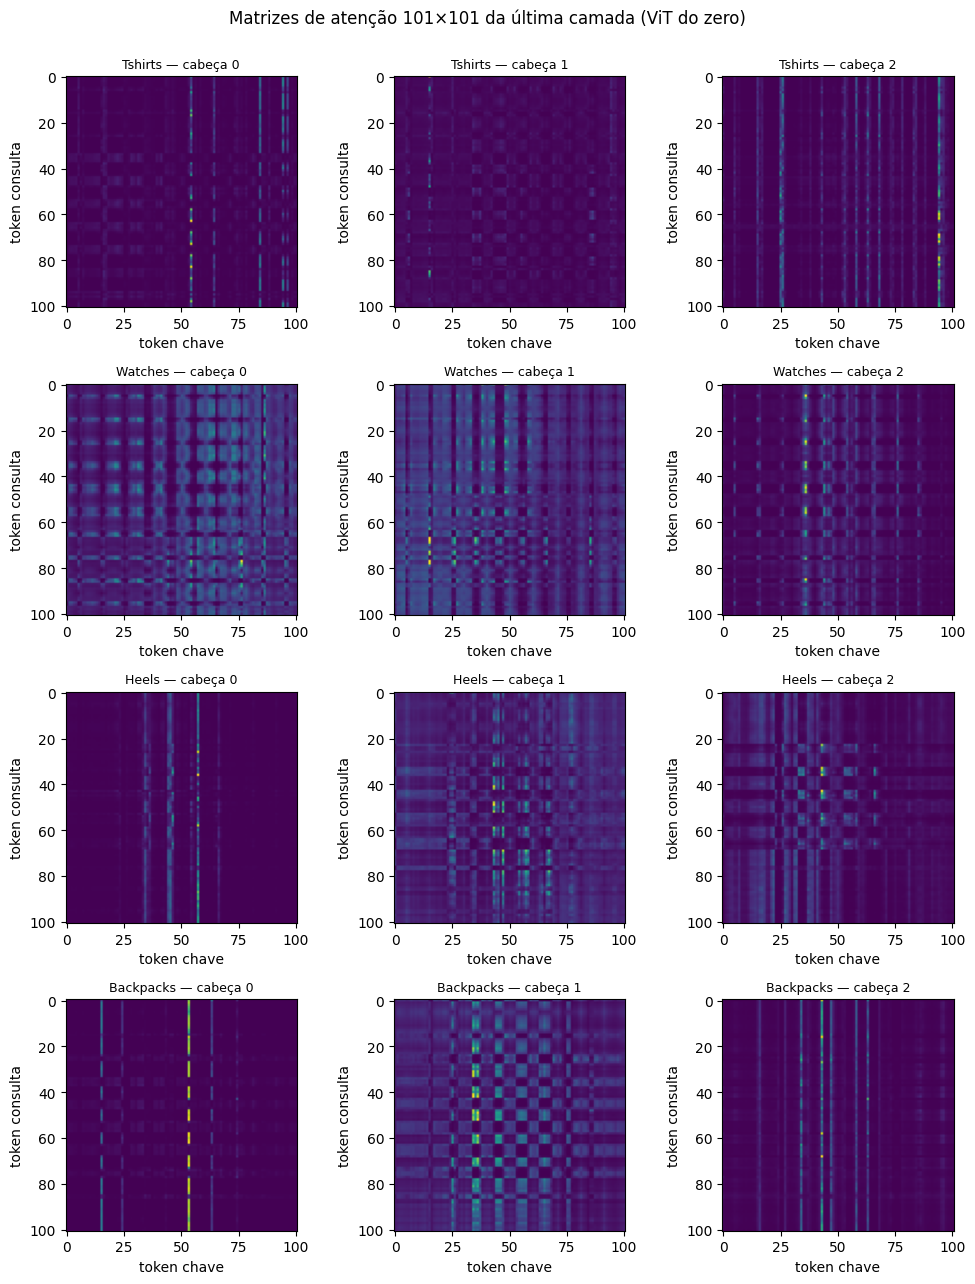

In [ ]:
demo_classes = [CLASS_NAMES.index(c) for c in ["Tshirts", "Watches", "Heels", "Backpacks"] if c in CLASS_NAMES]
demo_idx = []
for c in demo_classes:
    demo_idx.append(int(np.where(y_test_np == c)[0][0]))
demo_x = X_test[demo_idx]

scratch = results["ViT do zero"]
vit_scratch.eval()
with torch.no_grad():
    xb = prepare_batch(demo_x, False, scratch["mean"], scratch["std"], IMAGE_SIZE)
    logits_demo, attn_layers = vit_scratch(xb, return_attention=True)
attn_layers = [a.float().cpu() for a in attn_layers]
GRID = IMAGE_SIZE // 8


def attention_rollout(layers):
    tokens = layers[0].size(-1)
    rollout = torch.eye(tokens)
    for a in layers:
        a = a.mean(0)
        a = 0.5 * a + 0.5 * torch.eye(tokens)
        a = a / a.sum(-1, keepdim=True)
        rollout = a @ rollout
    return rollout[0, 1:]


def overlay(ax, image, heat, grid):
    heat = heat.reshape(1, 1, grid, grid)
    heat = F.interpolate(heat, size=image.shape[:2], mode="bilinear", align_corners=False)[0, 0].numpy()
    heat = (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)
    ax.imshow(image)
    ax.imshow(heat, cmap="jet", alpha=0.45)
    ax.axis("off")


fig, axes = plt.subplots(len(demo_idx), 3, figsize=(10, 3.2 * len(demo_idx)))
for r, i in enumerate(range(len(demo_idx))):
    last = attn_layers[-1][i]
    for h in range(3):
        axes[r, h].imshow(last[h].numpy(), cmap="viridis")
        axes[r, h].set_title(f"{CLASS_NAMES[demo_classes[r]]} — cabeça {h}", fontsize=9)
        axes[r, h].set_xlabel("token chave")
        axes[r, h].set_ylabel("token consulta")
plt.suptitle("Matrizes de atenção 101×101 da última camada (ViT do zero)", y=1.0)
plt.tight_layout()
plt.show()

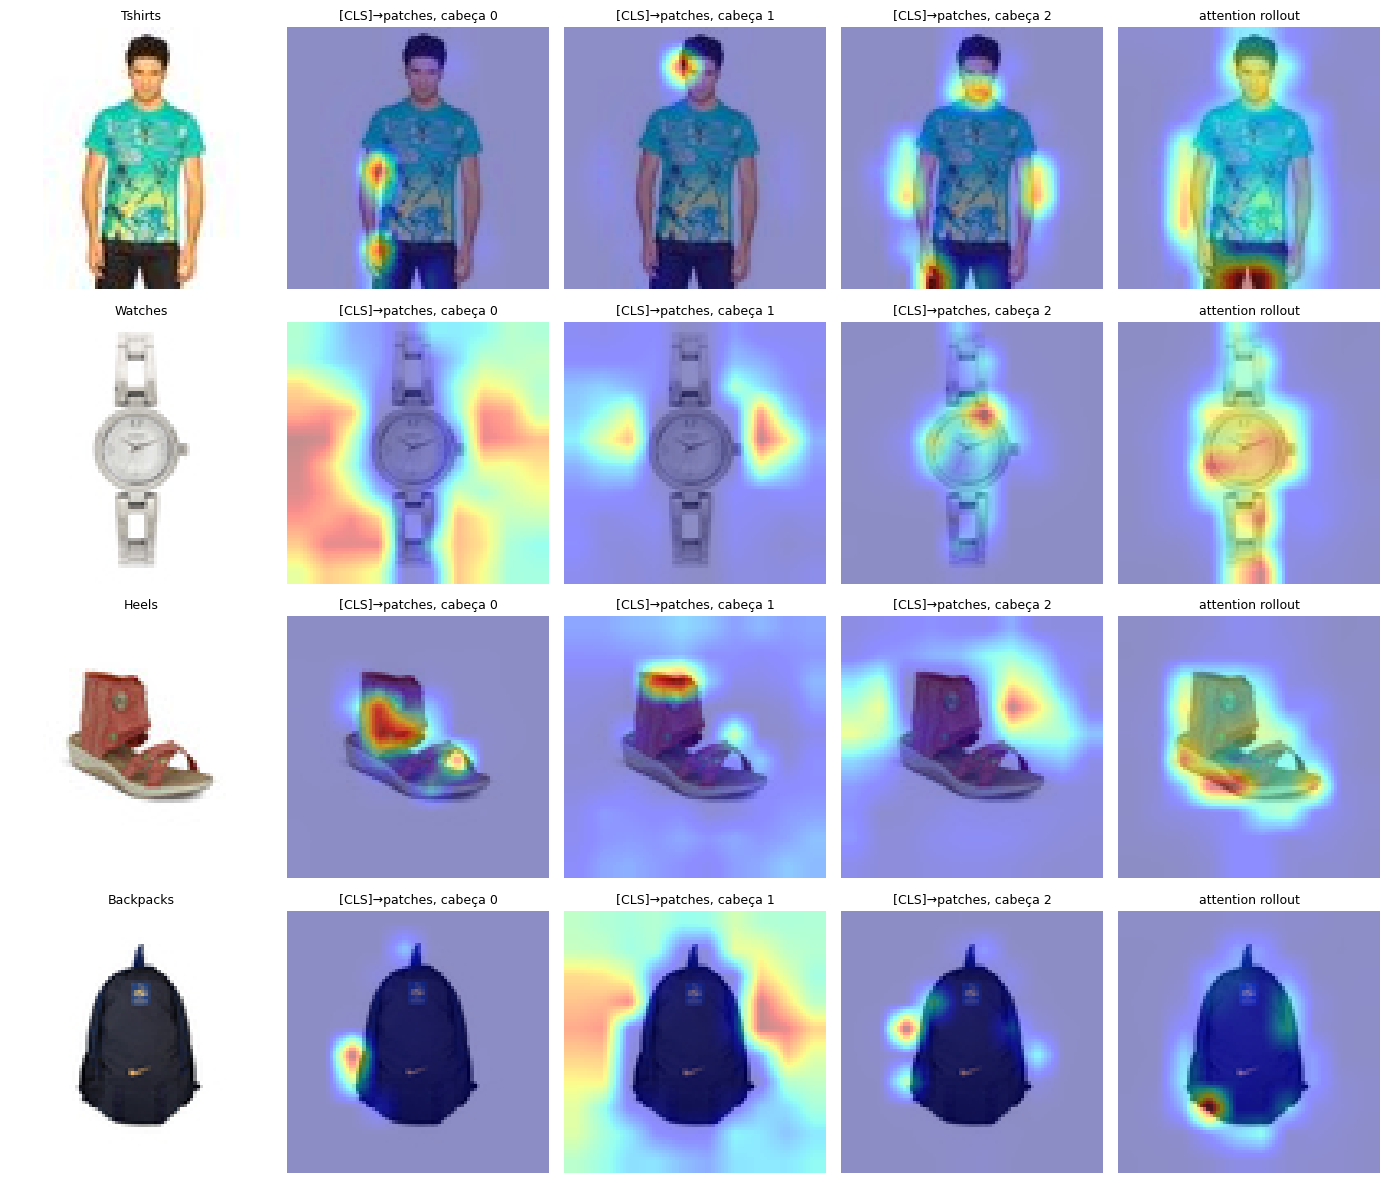

In [ ]:
fig, axes = plt.subplots(len(demo_idx), 5, figsize=(14, 3 * len(demo_idx)))
for r in range(len(demo_idx)):
    image = demo_x[r].permute(1, 2, 0).cpu().numpy()
    axes[r, 0].imshow(image)
    axes[r, 0].set_title(CLASS_NAMES[demo_classes[r]], fontsize=9)
    axes[r, 0].axis("off")
    layer_attn = [a[r] for a in attn_layers]
    for h in range(3):
        overlay(axes[r, 1 + h], image, layer_attn[-1][h, 0, 1:], GRID)
        axes[r, 1 + h].set_title(f"[CLS]→patches, cabeça {h}", fontsize=9)
    overlay(axes[r, 4], image, attention_rollout(layer_attn), GRID)
    axes[r, 4].set_title("attention rollout", fontsize=9)
plt.tight_layout()
plt.show()

### Atenção no ViT-B/16 pré-treinado

O mesmo procedimento é aplicado ao ViT-B/16 ajustado (grade 14×14, 12 cabeças por camada). Para obter os pesos de atenção, o modelo é recarregado com `attn_implementation="eager"` e recebe os pesos do melhor checkpoint.

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


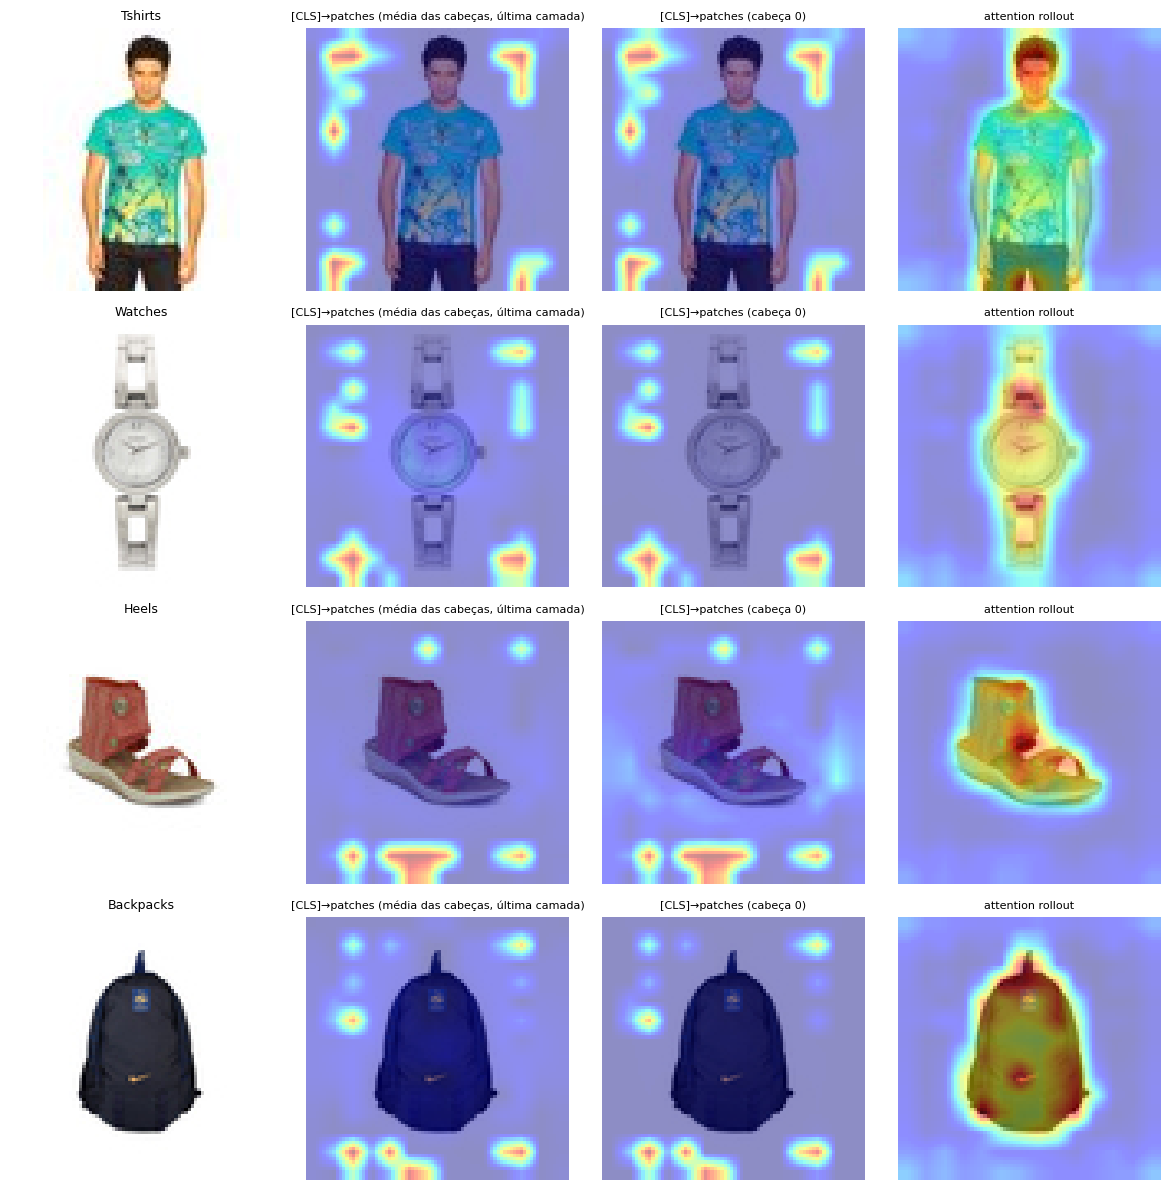

In [ ]:
vit_eager = HFViT(attn_implementation="eager")
vit_eager.load_state_dict(vit_pretrained.state_dict())
vit_eager.to(device).eval()

pre = results["ViT-B/16 pré-treinado"]
with torch.no_grad():
    xb = prepare_batch(demo_x, False, pre["mean"], pre["std"], 224)
    out = vit_eager.model(pixel_values=xb, output_attentions=True)
hf_layers = [a.float().cpu() for a in out.attentions]
HF_GRID = 224 // 16

fig, axes = plt.subplots(len(demo_idx), 4, figsize=(12, 3 * len(demo_idx)))
for r in range(len(demo_idx)):
    image = demo_x[r].permute(1, 2, 0).cpu().numpy()
    axes[r, 0].imshow(image)
    axes[r, 0].set_title(CLASS_NAMES[demo_classes[r]], fontsize=9)
    axes[r, 0].axis("off")
    layer_attn = [a[r] for a in hf_layers]
    overlay(axes[r, 1], image, layer_attn[-1].mean(0)[0, 1:], HF_GRID)
    axes[r, 1].set_title("[CLS]→patches (média das cabeças, última camada)", fontsize=8)
    overlay(axes[r, 2], image, layer_attn[-1][0, 0, 1:], HF_GRID)
    axes[r, 2].set_title("[CLS]→patches (cabeça 0)", fontsize=8)
    overlay(axes[r, 3], image, attention_rollout(layer_attn), HF_GRID)
    axes[r, 3].set_title("attention rollout", fontsize=8)
plt.tight_layout()
plt.show()

del vit_eager
torch.cuda.empty_cache()

### Embeddings posicionais aprendidos

Como o embedding posicional do ViT do zero é aprendível e inicializado de forma aleatória, é possível verificar se o modelo aprendeu a noção de vizinhança espacial: patches próximos na imagem devem ter embeddings posicionais mais parecidos (similaridade do cosseno).

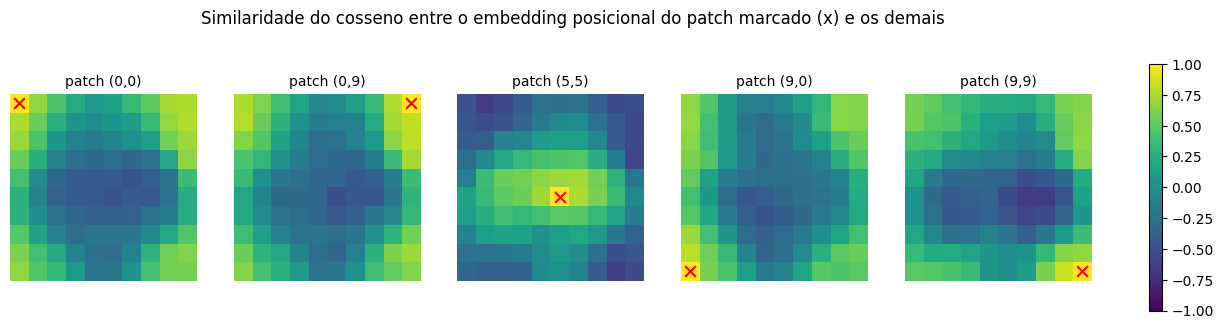

Correlação entre distância espacial e similaridade posicional: -0.262


In [ ]:
pos = vit_scratch.pos_embed.detach()[0, 1:].cpu()
pos = F.normalize(pos, dim=-1)
similarity = (pos @ pos.T).reshape(GRID, GRID, GRID, GRID)

anchors = [(0, 0), (0, GRID - 1), (GRID // 2, GRID // 2), (GRID - 1, 0), (GRID - 1, GRID - 1)]
fig, axes = plt.subplots(1, len(anchors), figsize=(15, 3.2))
for ax, (r, c) in zip(axes, anchors):
    im = ax.imshow(similarity[r, c].numpy(), cmap="viridis", vmin=-1, vmax=1)
    ax.scatter([c], [r], color="red", s=60, marker="x")
    ax.set_title(f"patch ({r},{c})", fontsize=10)
    ax.axis("off")
plt.colorbar(im, ax=axes, fraction=0.02)
plt.suptitle("Similaridade do cosseno entre o embedding posicional do patch marcado (x) e os demais", y=1.05)
plt.show()

rows_idx = torch.arange(GRID).repeat_interleave(GRID)
cols_idx = torch.arange(GRID).repeat(GRID)
dist = ((rows_idx[:, None] - rows_idx[None]).float() ** 2 + (cols_idx[:, None] - cols_idx[None]).float() ** 2).sqrt()
sim_flat = (pos @ pos.T)
mask = ~torch.eye(GRID * GRID, dtype=torch.bool)
corr = np.corrcoef(dist[mask].numpy(), sim_flat[mask].numpy())[0, 1]
print(f"Correlação entre distância espacial e similaridade posicional: {corr:.3f}")

### Análise da atenção

**ViT do zero (última camada).** As matrizes 101×101 mostram padrões distintos por cabeça. Algumas (por exemplo, cabeça 0 em Heels e Backpacks) concentram a atenção em **poucas colunas**, ou seja, poucos tokens-chave recebem a atenção de quase todos os tokens-consulta, como se funcionassem como pontos de agregação de informação global. Outras (cabeça 1 em Backpacks, cabeça 2 em Heels) exibem um **padrão de grade/xadrez**, típico de atenção entre grupos de patches com características semelhantes, e a cabeça 0 em Watches tem estrutura difusa e periódica. As três cabeças de uma mesma camada aprendem comportamentos diferentes, o que justifica ter várias cabeças em vez de uma única.

**Mapas [CLS]→patches e rollout (ViT do zero).** A atenção do `[CLS]` na última camada é **esparsa e específica por cabeça**: em Tshirts, uma cabeça olha o rosto, outra o braço e a barra da calça; em Heels, as cabeças 0 e 1 focam o cano e a fivela da sandália, regiões discriminativas do produto. Em Watches e Backpacks, algumas cabeças dispersam a atenção também pelo fundo branco, o que mostra que uma única cabeça não carrega a decisão sozinha. O **attention rollout** consolida as camadas e é mais coerente: destaca o corpo do produto (sandália, mochila, mostrador e pulseira do relógio, tronco da camiseta), embora em Tshirts parte da energia caia sobre braços e pernas, evidenciando que o modelo usa também o contexto do modelo-vestindo-a-peça.

**ViT-B/16 pré-treinado.** A atenção da última camada (média das cabeças ou cabeça 0) concentra-se em **patches do fundo e das bordas**, com pouca atenção ao objeto. Esse comportamento é conhecido em ViTs grandes: alguns tokens de fundo, de baixa informação local, passam a armazenar informação global e atraem atenção (tokens de alta norma). Por isso a atenção direta do `[CLS]` na última camada é um mau indicador do que o modelo usa. O **rollout**, que acumula todas as camadas, é muito mais interpretável: destaca claramente a sandália, a mochila inteira e o relógio com a pulseira, e atribui menos peso ao fundo branco que no ViT do zero. É uma boa ilustração de que mapas de atenção devem ser lidos com cuidado e que o rollout é mais confiável que a atenção bruta.

**Embeddings posicionais aprendidos.** Os embeddings posicionais, inicializados aleatoriamente, **adquiriram estrutura espacial**: o patch marcado é mais parecido com seus vizinhos imediatos do que com patches distantes (mapas centrados no patch de interesse), e a correlação entre distância espacial e similaridade é **negativa (−0,262)**, isto é, quanto mais longe, menos parecido. O mapa do patch central (5,5) mostra um halo circular de alta similaridade, e os patches dos cantos são parecidos entre si e com as bordas, padrão coerente com o fato de que a periferia dessas imagens é fundo branco. Ou seja, mesmo sem nenhuma informação de posição fornecida, o modelo aprendeu a noção de grade 2D e de vizinhança, que a convolução tem embutida por construção.

### Conclusões e limitações

- Com poucos dados, o **pré-treino foi decisivo**: +10,75 p.p. sobre o ViT do zero, com convergência em 1 a 4 épocas em vez de 60.
- O **ViT-B/16** teve a melhor acurácia (94,38%), mas sem diferença estatisticamente clara em relação à **ResNet-18** (92,80%), que treinou em 0,8 min e infere ~21× mais rápido; a escolha prática depende do custo aceitável.
- O ViT do zero é um modelo pequeno (2,7 M) e subajustado; mais épocas, mais dados ou pré-treino auto-supervisionado (MAE, DINO) tendem a reduzir a distância.
- **Limitações:** uma única divisão treino/validação/teste e uma única semente (sem barras de variância entre execuções); imagens de baixa resolução (80×80 e ~60×80 originais); no máximo 1.000 imagens por classe e 20 classes; rótulos de catálogo com ambiguidade entre categorias vizinhas; as comparações de tempo dependem da T4 e da configuração de cada experimento (resolução de entrada e épocas diferentes).

## 10. Pré-treino em texto (BERT) vs. imagem (ViT), DeiT e Swin

### Como o pré-treino do BERT difere do pré-treino do ViT

- **Objetivo.** O BERT é pré-treinado de forma **auto-supervisionada** com *masked language modeling* (prever tokens mascarados a partir do contexto bidirecional) e *next sentence prediction*; não precisa de rótulos humanos. O ViT original é pré-treinado de forma **supervisionada**, classificando imagens em grandes bases rotuladas (ImageNet-21k, JFT-300M); variantes recentes (MAE, DINO, BEiT) adotam objetivos auto-supervisionados análogos ao do BERT, como reconstruir patches mascarados.
- **Unidade de entrada.** Texto é discreto, com vocabulário finito (WordPiece); o BERT prevê uma distribuição sobre palavras. Imagens são contínuas, então os patches precisam de uma projeção linear e não há um "vocabulário" natural a ser predito.
- **Sinal de aprendizado.** Em texto, cada token mascarado é uma tarefa de predição rica e barata, e a linguagem tem estrutura sintática e semântica densa. Em imagens, pixels vizinhos são altamente redundantes, o que torna a reconstrução menos informativa e exige mascarar proporções maiores (≈75% no MAE).
- **Viés indutivo.** O ViT não tem localidade nem invariância a translação embutidas (ao contrário das CNNs), então depende muito mais de volume de dados no pré-treino. Foi o que se observou neste notebook: o ViT do zero com ~14 mil imagens fica abaixo dos modelos pré-treinados.
- **Uso posterior.** Em ambos, o pré-treino produz uma representação reutilizada por *fine-tuning* com uma cabeça nova (aqui, `Linear(768, 20)` sobre o `[CLS]`).

### DeiT e Swin Transformer

| Aspecto | ViT original | DeiT (Touvron et al., 2021) | Swin (Liu et al., 2021) |
|---|---|---|---|
| Dados de pré-treino | ImageNet-21k / JFT-300M (centenas de milhões de imagens) | Apenas ImageNet-1k (1,3 M) | ImageNet-1k ou 21k |
| Ideia central | Sequência plana de patches 16×16 com atenção global | Mesma arquitetura do ViT, treinada com **receita eficiente em dados**: augmentation forte (RandAugment, Mixup, CutMix), regularização e **destilação** | Atenção em **janelas locais deslocadas** (*shifted windows*) e representação **hierárquica** (patches fundidos entre estágios) |
| Token extra | `[CLS]` | `[CLS]` + **token de destilação** que aprende com um professor CNN | Sem `[CLS]`; pooling global médio no final |
| Complexidade da atenção | Quadrática no número de patches | Quadrática | **Linear** no tamanho da imagem (atenção restrita à janela) |
| Saída | Um único mapa de resolução fixa | Idem ao ViT | Mapas multi-escala, usáveis como *backbone* em detecção e segmentação |
| Quando usar | Muitos dados ou modelo pré-treinado disponível | Poucos dados e sem pré-treino em larga escala | Imagens de alta resolução e tarefas densas (detecção, segmentação) |

O DeiT mostra que o problema do ViT com poucos dados pode ser atenuado por receita de treino e destilação; o Swin reintroduz propriedades de CNN (localidade e hierarquia) dentro de um Transformer, reduzindo o custo e melhorando o desempenho em tarefas de predição densa.

## 11. Tempo total, referências e declaração de uso de IA

In [ ]:
total = time.time() - NOTEBOOK_START
print(f"Tempo total de execução do notebook: {total / 60:.1f} min")
if device.type == "cuda":
    print(f"Pico de memória de GPU alocada: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

Tempo total de execução do notebook: 18.6 min
Pico de memória de GPU alocada: 7.2 GB


### Referências

- Dosovitskiy, A. et al. *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale.* ICLR, 2021.
- Vaswani, A. et al. *Attention Is All You Need.* NeurIPS, 2017.
- Devlin, J. et al. *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.* NAACL, 2019.
- Touvron, H. et al. *Training data-efficient image transformers & distillation through attention (DeiT).* ICML, 2021.
- Liu, Z. et al. *Swin Transformer: Hierarchical Vision Transformer using Shifted Windows.* ICCV, 2021.
- Abnar, S.; Zuidema, W. *Quantifying Attention Flow in Transformers.* ACL, 2020.
- He, K. et al. *Deep Residual Learning for Image Recognition.* CVPR, 2016.
- Dataset: Aggarwal, P. *Fashion Product Images (Small).* Kaggle. https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small
- Modelo: `google/vit-base-patch16-224-in21k`, Hugging Face.

### Declaração de uso de IA

O assistente Claude (Anthropic) foi utilizado como apoio na estruturação do código e na revisão dos textos deste notebook.